# Embedding and search (KAN-97)
Gözde Nur Özdemir · ELIZA · Sprint 2

**What the course asks for in Sprint 2:** *"the most basic vector database and retrieval over your documents"*, with the parameters in `config/rag.yaml`, and by 11/11: *"retrieval returns passages for a handful of test questions"*.

**What this notebook does:** it turns our 105 chunks into vectors, stores them, and returns the 5 best chunks for a question. Every choice says where it comes from.

| Step | What | Where the choice comes from |
|---|---|---|
| 1 | Load the settings and the chunks | `config/rag.yaml` (course rule) |
| 2 | Prepare the text: nothing removed by default | Dickinson 2026, *Stop Removing Stopwords* |
| 3 | Which words BM25 already ignores (IDF) | the BM25 formula |
| 4 | A jury of three LLMs labels the frequent words | instructor's feedback; Verga et al. 2024, *Replacing Judges with Juries* |
| 5 | Does removing words help? Tested on my questions | Dickinson 2026: *"the burden of proof sits with removal"* |
| 6 | Which embedding model? Three models tested on my questions | design decision D10, model cards |
| 7 | Store them in Chroma | design decision D11 |
| 8 | Keyword index (BM25) | design decision D12 |
| 9 | Search: dense (E1) and hybrid (E2) | design decision D12, RRF paper |
| 9b | Dense, BM25 or hybrid? Tested on my questions | design decision D12 |
| 10 | My questions, one by one (11/11 check) | course halfway check |
| 11 | A picture of the chunks | my earlier retrieval project |

**Questions used:** only my questions on Annex III 3(b): **B-01 to B-06** for every score in this notebook, and the safety questions **B-S1 to B-S3** shown in step 10. The team's other questions are kept for the `val`/`test` split (KAN-53) and the measurement in KAN-99.

The measurement on the `val` questions (Recall@5, MRR, the instructor's RAG metrics, W&B) is the next task, KAN-99.

**Install once, in the terminal** (not in the notebook), in the same Python environment as Jupyter:
```
pip install sentence-transformers chromadb rank_bm25 pandas pyyaml requests scikit-learn umap-learn matplotlib
```

In [3]:
import csv, json, re
from collections import Counter
import numpy as np, pandas as pd, requests, yaml
pd.set_option("display.max_colwidth", None)
np.random.seed(42)

## 1. Load the settings and the chunks
All settings are in `config/rag.yaml`: the course asks for parameters there, not in the code. The chunks come from `src/chunking.ipynb`. The notebook works in two places: in the repository (opened from `src/`), or in one folder that holds `embedding.ipynb`, `rag.yaml`, `chunks.jsonl` and `eval-set-v1.csv`.

In [5]:
import os
IN_REPO = os.path.exists("../config/rag.yaml")      # opened from src/ in the repository, or from one folder with all files
P = lambda path: path if IN_REPO else os.path.basename(path)

CONFIG = yaml.safe_load(open(P("../config/rag.yaml")))
chunks = [json.loads(line) for line in open(P("../data/chunks.jsonl"), encoding="utf-8")]
ref_of = {c["chunk_id"]: c["ref"] for c in chunks}
print(len(chunks), "chunks")
CONFIG

105 chunks


{'chunking': {'strategy': 'structure',
  'source_file': 'CELEX_02024R1689-20260727_EN.html',
  'version_date': '27/07/2026',
  'celex': '02024R1689-20260727',
  'max_chars': 1500},
 'embedding': {'model': 'BAAI/bge-small-en-v1.5',
  'candidates': ['sentence-transformers/all-MiniLM-L6-v2',
   'BAAI/bge-small-en-v1.5',
   'BAAI/bge-base-en-v1.5'],
  'query_instruction': 'Represent this sentence for searching relevant passages: '},
 'vector_store': {'path': '../data/vector-store'},
 'bm25': {'remove': 'jury',
  'jury_words': ['a',
   'and',
   'for',
   'in',
   'of',
   'shall',
   'that',
   'the',
   'this',
   'to',
   'with']},
 'judge': {'jury': ['qwen3:4b', 'phi4-mini', 'gemma3:4b'],
  'url': 'http://localhost:11434/api/chat'},
 'retrieval': {'mode': 'hybrid', 'top_k': 5, 'candidates': 20, 'rrf_k': 60}}

## 2. Prepare the text: nothing is removed by default
**Dense search (embedding)** reads the full `embed_text`: heading + the sentence before a point + the provision. The model reads normal sentences, and small words change a rule: *"shall **not** be considered to be high-risk"* means the opposite without "not".

**Keyword search (BM25)** reads the same text in lower case, split into words. We **do not remove stopwords by default**. A 2026 study on court decisions (Dickinson, *Stop Removing Stopwords*) found that the usual stopword lists (scikit-learn, NLTK, spaCy) made legal text classification slightly worse in all 12 tests, and that even word-by-word tuned lists gave no measurable gain. Its rule: *"the burden of proof sits with removal"*: a word is removed only if removing it is shown to help (step 5).

In [7]:
words = lambda text: re.findall(r"[a-z0-9]+", text.lower())
example = next(c for c in chunks if c["chunk_id"] == "ART6-3-1")
print("TEXT:", example["text"][:150], "...")
print("BM25:", words(example["text"])[:18], "...")
print(sum(any(w in {"not", "no", "nor"} for w in words(c["text"])) for c in chunks), "of 105 chunks contain a negation")

TEXT: 3. By derogation from paragraph 2, an AI system referred to in Annex III shall not be considered to be high-risk where it does not pose a significant  ...
BM25: ['3', 'by', 'derogation', 'from', 'paragraph', '2', 'an', 'ai', 'system', 'referred', 'to', 'in', 'annex', 'iii', 'shall', 'not', 'be', 'considered'] ...
27 of 105 chunks contain a negation


**Comment:** Nothing is removed yet: BM25 sees “by”, “from” and “an”, and also “not”. 27 of the 105 chunks contain a negation, so a careless stopword list could change the meaning of about a quarter of the provisions.

## 3. Which words does BM25 already ignore?
BM25 gives every word a weight (IDF): a word in many chunks gets a weight close to 0, so it hardly counts in a search. For comparison, a word in only one chunk gets about 4.3. This is part of BM25 itself, so frequent words are already pushed down without any list. The table shows the **20 words with the lowest weight**, how many chunks and questions contain them. These 20 are only the candidates for step 4.

In [10]:
from rank_bm25 import BM25Okapi
questions = {r["id"]: r for r in csv.DictReader(open(P("../docs/eval/eval-set-v1.csv"), encoding="utf-8-sig"))}
in_q = Counter(w for q in questions.values() for w in set(words(q["question"])))
in_c = Counter(w for c in chunks for w in set(words(c["embed_text"])))

N = len(chunks)
idf = lambda n: np.log(1 + (N - n + 0.5) / (n + 0.5))     # BM25 word weight (as in Lucene / Elasticsearch)
weights = pd.DataFrame([{"word": w, "BM25 weight (IDF)": round(idf(n), 2), "% of chunks": round(100 * n / N),
                         "% of questions": round(100 * in_q[w] / len(questions))} for w, n in in_c.items()])
candidates = weights.sort_values("BM25 weight (IDF)").head(20).reset_index(drop=True)
candidates

,word,BM25 weight (IDF),% of chunks,% of questions
0,article,0.00,100,0
1,the,0.09,91,77
2,of,0.13,89,8
3,ai,0.16,86,73
4,in,0.28,76,23
5,to,0.30,74,62
6,shall,0.37,70,0
7,and,0.42,66,65
8,risk,0.44,65,46
9,paragraph,0.45,64,0


**Comment:** Frequent words already get very low weights: “article” is in every chunk (weight 0.00) and “the” in 91% (0.09), while a word in only one chunk gets about 4.3. But some low-weight words are in many questions (“ai” 73%, “risk” and “high” 46%), so frequency alone cannot decide what to drop.

## 4. A jury of three LLMs labels the candidates
The instructor asked us to let an LLM decide which frequent words are useless, with a **different model** than our answer model. Instead of one judge, we use a **jury of three small models from different companies**, and the majority wins. Verga et al. (2024, *Replacing Judges with Juries*) showed that a panel of three models from different families agrees better with people than one large judge (Cohen's kappa 0.76 vs 0.63 for GPT-4 on Natural Questions), has less bias towards its own family, and is cheaper; for yes/no labels they use the majority vote.

| Model | Company | Why |
|---|---|---|
| `qwen3:4b` | Alibaba | worked with thinking turned off in our model selection spike |
| `phi4-mini` | Microsoft | our fallback answer model in the spike (D9) |
| `gemma3:4b` | Google | a third family of the same size |

None is **Llama** (our answer model, D9) or **Claude** (used to draft the questions). Same prompt, three examples of each word from our chunks, temperature 0. Needs `ollama pull qwen3:4b`, `ollama pull phi4-mini`, `ollama pull gemma3:4b`.

In [13]:
PROMPT = """This word appears in many EU AI Act provisions. Examples:
{examples}
Should a keyword search IGNORE it (common wording that does not help to find the right provision)
or KEEP it (a question can depend on it)? If in doubt, KEEP.
Answer in one line: IGNORE or KEEP, then a reason of at most 12 words.
WORD: {word}"""

installed = [m["name"] for m in requests.get(CONFIG["judge"]["url"].replace("/api/chat", "/api/tags")).json()["models"]]
missing = [m for m in CONFIG["judge"]["jury"] if not any(i.startswith(m) for i in installed)]
assert not missing, f"Run in the terminal first: {'  '.join('ollama pull ' + m for m in missing)}"

def ask(model, prompt):
    """The final answer of a model in Ollama: temperature 0, thinking off for Qwen3."""
    body = {"model": model, "stream": False, "messages": [{"role": "user", "content": prompt}],
            "options": {"temperature": 0, "num_predict": 2000}}     # room to finish thinking if Ollama cannot switch it off
    if model.startswith("qwen3"):
        body["think"] = False
        body["messages"][0]["content"] += " /no_think"         # Qwen3's own switch, also works with older Ollama
    answer = requests.post(CONFIG["judge"]["url"], json=body, timeout=300).json()
    if "error" in answer:
        raise RuntimeError(f"Ollama, {model}: {answer['error']}")
    text = answer["message"]["content"]
    if model.startswith("qwen3") and "</think>" not in text and text.lstrip().lower().startswith(("okay", "we are", "hmm")):
        return "UNCLEAR (thinking did not finish)"
    return text.split("</think>")[-1].strip()                  # keep only the final answer, after any thinking

def label(text):
    """IGNORE or KEEP if the final answer starts with it, otherwise UNCLEAR."""
    m = re.match(r"\W*(IGNORE|KEEP)\b", text.upper())
    return m[1] if m else "UNCLEAR"

def examples(word):
    return "\n".join([f'- {c["ref"]}: {c["text"][:150]}...' for c in chunks if word in words(c["text"])][:3])

jury = candidates[["word", "% of questions"]].copy()
for model in CONFIG["judge"]["jury"]:
    answers = []
    for n, w in enumerate(jury["word"], 1):
        answers.append(ask(model, PROMPT.format(examples=examples(w), word=w)))
        print(f"{model} {n}/{len(jury)}: {w} -> {answers[-1][:60]}")
    jury[model] = [label(a) for a in answers]
    jury[model + " reason"] = answers
models = CONFIG["judge"]["jury"]
jury["majority"] = np.where((jury[models] == "IGNORE").sum(axis=1) >= 2, "IGNORE", "KEEP")
JURY_IGNORE = set(jury.loc[jury["majority"] == "IGNORE", "word"])
print("The jury would ignore:", sorted(JURY_IGNORE))
print("Votes per model:", {m: jury[m].value_counts().to_dict() for m in models})
print("Models that gave the same label to every word (they do not tell words apart):",
      [m for m in models if jury[m].nunique() == 1] or "none")
jury[["word", "% of questions", *models, "majority"]]

qwen3:4b 1/20: article -> KEEP, standard legal term for provisions.
qwen3:4b 2/20: the -> IGNORE  
common stop word, no meaning for search
qwen3:4b 3/20: of -> IGNORE  
Common preposition, no specificity
qwen3:4b 4/20: ai -> KEEP, core term for AI systems in all provisions
qwen3:4b 5/20: in -> IGNORE  
common preposition in legal text
qwen3:4b 6/20: to -> IGNORE  
Common placeholder, no legal relevance in provision
qwen3:4b 7/20: shall -> IGNORE  
Common legal verb, not specific to provisions.
qwen3:4b 8/20: and -> IGNORE  
common conjunction, no specific meaning
qwen3:4b 9/20: risk -> KEEP, Central to high-risk AI classification
qwen3:4b 10/20: paragraph -> KEEP (Identifies numbered sections in AI Act provisions.)
qwen3:4b 11/20: systems -> KEEP, core term in AI Act scope definitions
qwen3:4b 12/20: high -> KEEP, high is essential for high-risk AI classification in E
qwen3:4b 13/20: system -> KEEP, Core term in AI Act definitions
qwen3:4b 14/20: or -> KEEP, or connects critical altern

,word,% of questions,qwen3:4b,phi4-mini,gemma3:4b,majority
0,article,0,KEEP,KEEP,IGNORE,KEEP
1,the,77,IGNORE,KEEP,IGNORE,IGNORE
2,of,8,IGNORE,KEEP,IGNORE,IGNORE
3,ai,73,KEEP,KEEP,IGNORE,KEEP
4,in,23,IGNORE,KEEP,IGNORE,IGNORE
5,to,62,IGNORE,KEEP,IGNORE,IGNORE
6,shall,0,IGNORE,KEEP,IGNORE,IGNORE
7,and,65,IGNORE,KEEP,IGNORE,IGNORE
8,risk,46,KEEP,KEEP,IGNORE,KEEP
9,paragraph,0,KEEP,KEEP,IGNORE,KEEP


**Comment:** The jury would ignore 11 function words (for example “the”, “of”, “and”, “shall”) and keeps the words our questions depend on, such as “ai”, “risk” and “high” (in 46–73% of the questions). Only Qwen3-4B told the words apart: phi4-mini answered KEEP and gemma3 answered IGNORE for almost every word, so the majority is the same as Qwen’s vote.

## 5. Does removing words help? Tested on my questions
Following the *burden of proof* rule, we compare three versions of BM25 on my questions **B-01 to B-06** (Annex III 3(b), planned for the `val` split):
- **none:** nothing removed (the default)
- **jury:** the words the jury marked IGNORE are removed
- **stopwords:** the scikit-learn stopword list is removed, but "not", "no", "nor" are kept

Scores, as in the instructor's slides (*"compute Recall@k / MRR on gold IDs"*): **Recall@5** = share of the gold provisions in the top 5; **MRR** = 1 / rank of the first correct chunk; **Precision@5** = share of the top 5 chunks that are gold provisions. A question with 4 gold provisions and 2 of them in the top 5 counts as Recall 0.5, not as a success: partial hits are counted as partial, and the unrelated chunks lower Precision.

**Rule:** a version replaces "none" only if it is better on Recall@5 or MRR and worse on neither. Six questions are few (one question changes Recall@5 by about 0.17), so this is a first check; it is repeated on all the team's `val` questions in KAN-99.

In [16]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
REMOVE = {"none": set(), "jury": JURY_IGNORE, "stopwords": set(ENGLISH_STOP_WORDS) - {"not", "no", "nor"}}
ref_of = {c["chunk_id"]: c["ref"] for c in chunks}
dev = [questions[q] for q in ["B-01", "B-02", "B-03", "B-04", "B-05", "B-06"]]

def bm25_search(remove):
    index = BM25Okapi([[w for w in words(c["embed_text"]) if w not in remove] for c in chunks])
    return lambda q: [chunks[n]["chunk_id"] for n in np.argsort(-index.get_scores([w for w in words(q) if w not in remove]))]

def score(search, k=5):
    """Recall@k, MRR and Precision@k over my questions B-01 to B-06."""
    recall, rr, precision = [], [], []
    for q in dev:
        gold = [g.strip() for g in q["gold_source"].split(";")]
        refs = [ref_of[c] for c in search(q["question"])[:k]]
        hit = lambda r: any(r.startswith(g) or g.startswith(r) for g in gold)
        recall.append(np.mean([any(r.startswith(g) or g.startswith(r) for r in refs) for g in gold]))
        rr.append(next((1 / n for n, r in enumerate(refs, 1) if hit(r)), 0))
        precision.append(np.mean([hit(r) for r in refs]))
    return {"Recall@5" if k == 5 else f"Recall@{k}": round(np.mean(recall), 2), "MRR": round(np.mean(rr), 2),
            "Precision@5" if k == 5 else f"Precision@{k}": round(np.mean(precision), 2)}

test = pd.DataFrame([{"version": v, **score(bm25_search(words_out))} for v, words_out in REMOVE.items()]).set_index("version")
better = lambda v: (test.loc[v] >= test.loc["none"]).all() and (test.loc[v] > test.loc["none"]).any()
CHOSEN = next((v for v in ["jury", "stopwords"] if better(v)), "none")
print("Chosen:", CHOSEN, "(write it in config/rag.yaml, bm25: remove)")
test

Chosen: jury (write it in config/rag.yaml, bm25: remove)


,Recall@5,MRR
version,,
none,0.25,0.17
jury,0.33,0.25
stopwords,0.29,0.26


**Comment:** Removing the jury’s 11 words raised Recall@5 from 0.25 to 0.33 and MRR from 0.17 to 0.25, so by our rule BM25 now ignores them. The standard stopword list was close (0.29 and 0.26) but lower on Recall@5; with six questions this is a first check, repeated on the val split in KAN-99.

## 6. Which embedding model? Tested on my questions
An embedding model turns a text into a list of numbers (a vector); texts with a similar meaning get similar numbers, even when they share no words. A question like *"our AI grades exams"* can then find Annex III 3(b) (*"evaluate learning outcomes"*).

The design document (D10) compared three open models that run on a CPU and chose `bge-base-en-v1.5`, based on published results, and said it would be checked on our questions. We check it here: each model embeds the 105 chunks and searches my questions B-01 to B-06.

| Model | Numbers per text | In D10 |
|---|---|---|
| `sentence-transformers/all-MiniLM-L6-v2` | 384 | very small, weaker on retrieval |
| `BAAI/bge-small-en-v1.5` | 384 | small, proposed in Spike 01 |
| `BAAI/bge-base-en-v1.5` | 768 | chosen: stronger on retrieval, MIT licence |

The bge models expect a short instruction in front of a question (their model card); MiniLM does not. **Rule:** the model with the best Recall@5 (then MRR) wins; if they are equal, we keep the design document's choice.

In [19]:
import time
from sentence_transformers import SentenceTransformer

def dense_search(model, vectors, instruction):
    """A search that ranks the chunks by cosine similarity to the question."""
    return lambda q: [chunks[n]["chunk_id"] for n in np.argsort(-(vectors @ model.encode([instruction + q], normalize_embeddings=True)[0]))]

models, rows = {}, []
for name in CONFIG["embedding"]["candidates"]:
    model = SentenceTransformer(name, device="cpu")
    start = time.time()
    vectors = model.encode([c["embed_text"] for c in chunks], normalize_embeddings=True)
    seconds = round(time.time() - start, 1)
    instruction = CONFIG["embedding"]["query_instruction"] if "bge" in name else ""
    models[name] = (model, vectors, instruction)
    rows.append({"model": name, "numbers per text": vectors.shape[1], **score(dense_search(*models[name])), "seconds for 105 chunks": seconds})

model_test = pd.DataFrame(rows).sort_values(["Recall@5", "MRR"], ascending=False)
best = model_test.iloc[0]
tie = model_test[(model_test["Recall@5"] == best["Recall@5"]) & (model_test["MRR"] == best["MRR"])]["model"]
EMBEDDING = CONFIG["embedding"]["model"] if CONFIG["embedding"]["model"] in set(tie) else best["model"]
model, vectors, INSTRUCTION = models[EMBEDDING]
print("Chosen:", EMBEDDING, "(write it in config/rag.yaml, embedding: model)")
model_test

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Chosen: BAAI/bge-small-en-v1.5 (write it in config/rag.yaml, embedding: model)


,model,numbers per text,Recall@5,MRR,seconds for 105 chunks
1,BAAI/bge-small-en-v1.5,384,0.48,0.26,1.3
2,BAAI/bge-base-en-v1.5,768,0.40,0.53,3.6
0,sentence-transformers/all-MiniLM-L6-v2,384,0.31,0.21,0.6


**Comment:** bge-small found the most gold provisions (Recall@5 0.48 against 0.40 for bge-base and 0.31 for MiniLM), so it wins by our rule, and it embeds the chunks three times faster than bge-base. bge-base put the first correct chunk much higher (MRR 0.53 against 0.26), so the two are compared again on the val split in KAN-99.

**Quick check of the chosen model:** two points of the same rule should be closer (higher number) than two different topics.

In [22]:
i = {c["chunk_id"]: n for n, c in enumerate(chunks)}
print("ART6-3-a vs ART6-3-b (two points of the same rule):", round(float(vectors[i["ART6-3-a"]] @ vectors[i["ART6-3-b"]]), 2))
print("ART6-3-a vs ART113-3-c-i (a different topic):      ", round(float(vectors[i["ART6-3-a"]] @ vectors[i["ART113-3-c-i"]]), 2))
embed = lambda texts: model.encode(texts, normalize_embeddings=True)

ART6-3-a vs ART6-3-b (two points of the same rule): 0.96
ART6-3-a vs ART113-3-c-i (a different topic):       0.75


## 7. Store them in Chroma
Chroma (D11) keeps the vectors, the texts and the metadata, and returns the closest chunks with cosine distance. It is saved in `data/vector-store/`; it is not in Git, because this notebook rebuilds it in seconds.

In [24]:
import chromadb
store = chromadb.PersistentClient(path=P(CONFIG["vector_store"]["path"]))
if "chunks" in [c.name for c in store.list_collections()]:
    store.delete_collection("chunks")
col = store.create_collection("chunks", metadata={"hnsw:space": "cosine"})
col.add(ids=[c["chunk_id"] for c in chunks], embeddings=vectors.tolist(), documents=[c["text"] for c in chunks],
        metadatas=[{"ref": c["ref"], "version_date": c["version_date"]} for c in chunks])
print(col.count(), "chunks stored")

105 chunks stored


## 8. Keyword index (BM25)
BM25 (D12) gives a high score to chunks that share the question's words, especially rare ones. It finds exact terms such as "Annex III" or "Article 113" that the embedding can miss. It uses the version chosen in step 5.

In [26]:
from rank_bm25 import BM25Okapi
keep = lambda text: [w for w in words(text) if w not in REMOVE[CHOSEN]]
bm25 = BM25Okapi([keep(c["embed_text"]) for c in chunks])
print("BM25 index over", len(chunks), "chunks")

BM25 index over 105 chunks


## 9. Search: dense (E1) and hybrid (E2)
- **Dense (E1, the baseline):** the closest vectors in Chroma.
- **Hybrid (E2):** the dense list and the BM25 list joined with Reciprocal Rank Fusion: each chunk gets `1 / (60 + rank)` from each list, and the two are added. 60 is the value from the RRF paper (Cormack et al., 2009).

Both return the top 5 (`top_k`); which one we keep, and whether 5 is right, is measured on the `val` questions in KAN-99.

In [28]:
R = CONFIG["retrieval"]

def dense(question):
    q = embed([INSTRUCTION + question])[0]
    return col.query(query_embeddings=[q.tolist()], n_results=R["candidates"])["ids"][0]

def keyword(question):
    return [chunks[n]["chunk_id"] for n in np.argsort(-bm25.get_scores(keep(question)))[:R["candidates"]]]

def hybrid(question):
    rrf = Counter()
    for ranked in (dense(question), keyword(question)):
        for rank, cid in enumerate(ranked, 1):
            rrf[cid] += 1 / (R["rrf_k"] + rank)
    return [cid for cid, _ in rrf.most_common()]          # full ranking; the top_k are taken by the caller

[ref_of[c] for c in hybrid("Is an AI tool that grades students' essays high-risk?")[:R["top_k"]]]

['Annex III, point 3(d)',
 'Article 6(3), third subparagraph',
 'Article 6(3), second subparagraph, point (d)',
 'Article 6(4)',
 'Article 6(2)']

**Comment:** For an essay-grading question, hybrid search returns Annex III 3(d) (exam monitoring) first, but not 3(b) (evaluating learning outcomes), the point that really covers grading. The two points use very similar words, so neighbouring use cases are still confused; step 9b and step 10 show how often this happens.

## 9b. Dense, BM25 or hybrid? Tested on my questions
The three ways of searching, scored like in steps 5 and 6 on B-01 to B-06. The design document plans dense search as the baseline (E1) and hybrid as the first improvement (E2).

In [31]:
pd.DataFrame([{"search": name, **score(fn)} for name, fn in [("dense (E1)", dense), ("BM25", keyword), ("hybrid (E2)", hybrid)]])

,search,Recall@5,MRR
0,dense (E1),0.48,0.26
1,BM25,0.33,0.25
2,hybrid (E2),0.52,0.45


**Comment:** Hybrid search is the best on both scores (Recall@5 0.52, MRR 0.45): it finds a few more gold provisions than dense search (0.48) and puts the first one much higher (0.45 against 0.26). BM25 alone is the weakest (0.33), so the baseline keeps hybrid search, as planned in the design document (E2), and KAN-99 checks it on the val split.

## 9c. How many chunks should come back? (top-k)
Some of my questions need several provisions: B-05 needs eight Articles (8 to 15), but only 5 chunks come back, so it can never reach Recall 1. The design document (D12) plans to choose top-k from 3, 5 or 8. More chunks find more gold provisions but also bring more unrelated ones (lower Precision) and more text for the answer model to read.

In [ ]:
topk = pd.DataFrame([{"top-k": k, **dict(zip(["Recall", "MRR", "Precision"], score(hybrid, k).values()))} for k in [3, 5, 8]])
topk

**Comment:** _(write 1–2 sentences after running)_

## 10. My questions, one by one (11/11 check)
For each of my questions: the top 5 chunks of each search, and the **gold source**; ✓ = a gold provision. B-01 to B-06 should find their gold provisions. B-S1 to B-S3 are safety questions (refuse, out of scope, no answer in the law): the search still returns chunks, and the answer step must refuse or say that the law does not answer them.

In [34]:
def show(ids, gold):
    parts = [g.strip() for g in gold.split(";")]
    return " | ".join(("✓ " if any(ref_of[c].startswith(g) or g.startswith(ref_of[c]) for g in parts) else "") + ref_of[c] for c in ids[:5])

mine = ["B-01", "B-02", "B-03", "B-04", "B-05", "B-06", "B-S1", "B-S2", "B-S3"]
for q in mine:
    question, gold = questions[q]["question"], questions[q]["gold_source"]
    print(f"{q}: {question}\n  GOLD:   {gold}")
    for name, fn in [("dense", dense), ("BM25", keyword), ("hybrid", hybrid)]:
        print(f"  {name:7} {show(fn(question), gold)}")
    print()

B-01: We made a tool that only takes the grades teachers already gave and calculates the weighted average. Is this still a high-risk AI system?
  GOLD:   Article 6(2); Article 6(3), first subparagraph; Article 6(3), second subparagraph, point (a); Article 6(3), third subparagraph
  dense   Annex III, point 3(b) | Annex III, point 3(c) | Annex III, point 3(d) | Annex III, point 3(a) | ✓ Article 6(3), third subparagraph
  BM25    Article 9(3) | Article 2(2) | Article 10(6) | Article 14(4) | Article 16, point (h)
  hybrid  Article 10(6) | ✓ Article 6(3), third subparagraph | Article 6(4) | ✓ Article 6(3), second subparagraph, point (a) | Article 6(3), second subparagraph, point (b)

B-02: Our AI only checks the exams that teachers have already written and points out typos and unclear questions. Is our product high-risk under the AI Act or not? Just tell us yes or no.
  GOLD:   Article 6(3), first subparagraph; Article 6(3), second subparagraph, point (b); Article 6(4); Article 49(2)
  den

**Comment:** Hybrid search finds at least one gold provision for five of my six questions and both for B-03; B-05 is the hardest, because its answer needs eight Articles and only five chunks come back. The clearest failure is B-06: no search finds Article 113 (the dates), so date questions are a weak spot for KAN-99. For the safety questions the search returns related provisions (Article 6(3) for B-S1, Article 15 for B-S3) and nothing about fines for B-S2, which is outside our corpus, so the answer step must refuse, redirect or say that the law gives no number.

## 11. A picture of the chunks
As in my earlier retrieval project, UMAP draws the numbers of each chunk (384 with bge-small) on a page. Chunks with a similar meaning should be close; each colour is one area of our provision list.

/opt/anaconda3/envs/pyspark_hw3/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


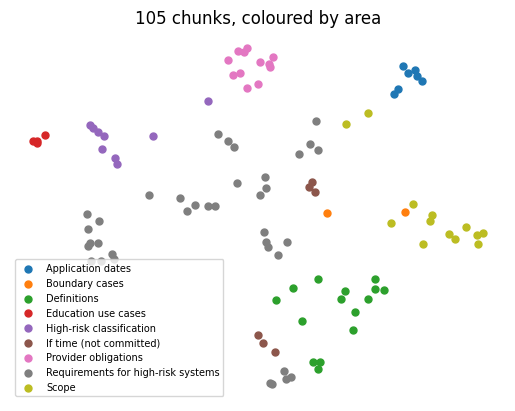

In [37]:
import umap, matplotlib.pyplot as plt
xy = umap.UMAP(n_neighbors=10, random_state=42).fit_transform(vectors)
for area in sorted({c["area"] for c in chunks}):
    pts = xy[[c["area"] == area for c in chunks]]
    plt.scatter(pts[:, 0], pts[:, 1], s=25, label=area)
plt.legend(fontsize=7); plt.title("105 chunks, coloured by area"); plt.axis("off"); plt.show()

**Comment:** The chunks group by area: the application dates, the provider obligations, the definitions and the four education use cases (Annex III, point 3) each form their own tight group. The requirements for high-risk systems (Articles 8–15) are spread in the middle because they share much of their wording, which fits the search mixing them up in B-05.

## Next: KAN-99
- Split the questions into `val` and `test` (KAN-53, 11/11).
- Repeat step 5 (removing words or not) on all the team's `val` questions.
- On every `val` question: Recall@5 and MRR (instructor's slides: *"compute Recall@k / MRR on gold IDs"*), dense (E1) vs hybrid (E2), and top-k 3, 5 or 8.
- The instructor's RAG metrics: Context Entities Recall (*"for fact-heavy text such as regulations"*) and, with the generated answers, Faithfulness.
- Everything logged in W&B; the baseline experiment card is KAN-100.
- Questions that need several provisions (B-05, multi-hop questions like B-03 and B-06; the instructor's slides: *"the retriever has to find every document in the chain"*) can be tested as Sprint 3 experiments, for example **query decomposition** (an LLM splits the question into one sub-question per provision and each is searched) or **MMR** (Maximal Marginal Relevance, Carbonell & Goldstein 1998: the top chunks are chosen to be relevant **and** different from each other, so five points of the same Article do not fill the list).